In [1]:
!pip install -q wfdb

import os, shutil, warnings
import numpy as np, pandas as pd, wfdb, joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay, f1_score, accuracy_score, balanced_accuracy_score,
                             matthews_corrcoef, recall_score, precision_score, classification_report)
warnings.filterwarnings("ignore")

DATA = "/content/data"
REPORT = "report"; os.makedirs(REPORT, exist_ok=True)
WIN = 300                            # 5-minute HRV window
OFFSETS = np.arange(60, 1801, 120)   # windows end 1..29 min before VF onset
BEATS = set("NLRBAaJSVFejnE/fQ")
NAMES = ["mean_rr", "sdnn", "rmssd", "pnn50", "sd1", "sd2", "sd1_sd2"]
CLS = ["Normal", "Pre-arrest"]; COL = ["tab:green", "tab:red"]
# VF onset (elapsed time) per SDDB record, from the dataset's index page. 40, 42, 49 have no VF.
ONSET = {"30": "07:54:33", "31": "13:42:24", "32": "16:45:18", "33": "04:46:19", "34": "06:35:44",
         "35": "24:34:56", "36": "18:59:01", "37": "01:31:13", "38": "08:01:54", "39": "04:37:51",
         "41": "02:59:24", "43": "15:37:11", "44": "19:38:45", "45": "18:09:17", "46": "03:41:47",
         "47": "06:13:01", "48": "02:29:40", "50": "11:45:43", "51": "22:58:23", "52": "02:32:40"}

# ---- download only what is needed (headers + annotations for all records, signal for one record each)
sd = list(ONSET)
nrecs = sorted(wfdb.get_record_list("nsrdb"))
need = {"sddb": [f"{r}.hea" for r in sd] + [f"{r}.ari" for r in sd] + [f"{sd[0]}.dat"],
        "nsrdb": [f"{r}.hea" for r in nrecs] + [f"{r}.atr" for r in nrecs] + [f"{nrecs[0]}.dat"]}
for db, files in need.items():
    os.makedirs(f"{DATA}/{db}", exist_ok=True)
    try:
        wfdb.dl_files(db, f"{DATA}/{db}", files)
    except Exception as e:                       # fallback: full database download (large)
        print("dl_files failed:", e, "-> downloading the full", db)
        wfdb.dl_database(db, f"{DATA}/{db}")
print("using data folder:", DATA, "|", {d: len(os.listdir(f"{DATA}/{d}")) for d in ["sddb", "nsrdb"]}, "files")

Finished downloading files
Finished downloading files
using data folder: /content/data | {'sddb': 41, 'nsrdb': 37} files


In [2]:
def hms(s):
    h, m, x = map(int, s.split(":")); return h * 3600 + m * 60 + x


def beat_times(rec, db):
    h = wfdb.rdheader(f"{DATA}/{db}/{rec}")
    a = wfdb.rdann(f"{DATA}/{db}/{rec}", "ari" if db == "sddb" else "atr")
    return np.array([s for s, c in zip(a.sample, a.symbol) if c in BEATS]) / h.fs


def feats(t, start, end):
    rr = np.diff(t[(t > start) & (t <= end)])
    rr = rr[(rr > 0.3) & (rr < 2.0)]
    if len(rr) < 150:
        return None
    rr = rr[np.abs(rr / np.median(rr) - 1) < 0.3]      # drop ectopic-like beats
    d = np.diff(rr)
    sd1 = np.std(d) / np.sqrt(2)
    sd2 = np.sqrt(max(2 * np.var(rr) - sd1 ** 2, 0))
    return [rr.mean(), rr.std(), np.sqrt(np.mean(d ** 2)), np.mean(np.abs(d) > 0.05), sd1, sd2, sd1 / (sd2 + 1e-9)]


def save(name):
    plt.tight_layout(); plt.savefig(f"{REPORT}/{name}.png", dpi=200); plt.show()


rows = []
for rec in ONSET:
    if not os.path.exists(f"{DATA}/sddb/{rec}.hea"):
        continue
    t, on = beat_times(rec, "sddb"), hms(ONSET[rec])
    for o in OFFSETS:
        f = feats(t, on - o - WIN, on - o) if on - o - WIN > 0 else None
        if f: rows.append(f + [1, "sddb" + rec, o / 60])
for rec in sorted(f[:-4] for f in os.listdir(f"{DATA}/nsrdb") if f.endswith(".hea")):
    t = beat_times(rec, "nsrdb")
    for end in 7200 + OFFSETS - OFFSETS[0]:
        f = feats(t, end - WIN, end)
        if f: rows.append(f + [0, "nsrdb" + rec, np.nan])
df = pd.DataFrame(rows, columns=NAMES + ["y", "rec", "mins"])
X, y, g = df[NAMES].values, df.y.values, df.rec.values
print(f"windows {len(df)} | pre-arrest {y.sum()} | normal {(y == 0).sum()} | records {df.rec.nunique()}")
df.to_csv(f"{REPORT}/features_dataset.csv", index=False)

windows 570 | pre-arrest 300 | normal 270 | records 38


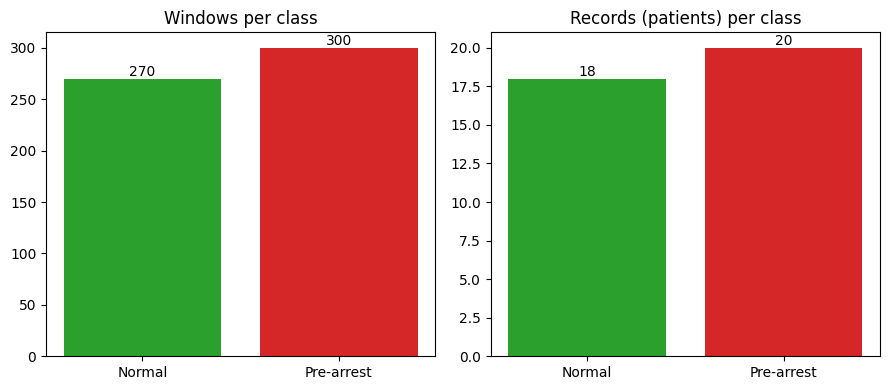

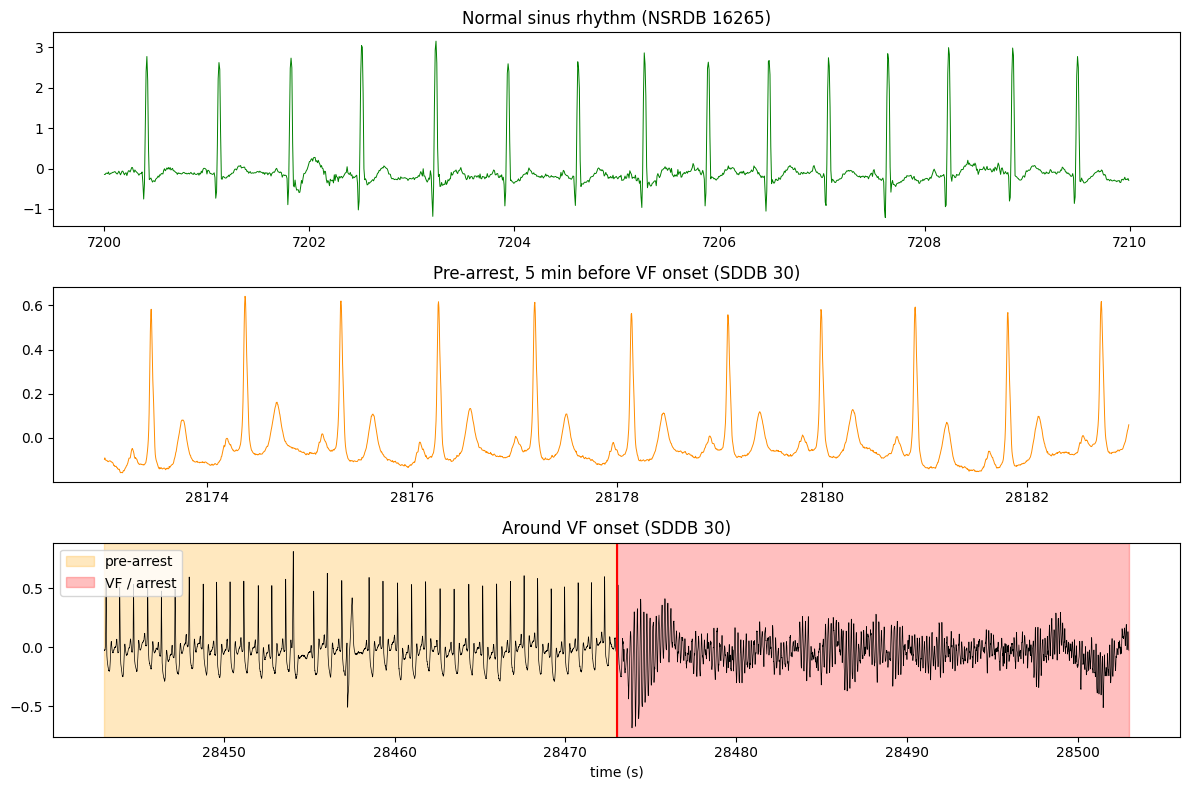

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, vals, ttl in [(ax[0], df.y.value_counts().sort_index().values, "Windows per class"),
                     (ax[1], df.groupby("y").rec.nunique().values, "Records (patients) per class")]:
    a.bar_label(a.bar(CLS, vals, color=COL)); a.set_title(ttl)
save("01_class_distribution")


def ecg(db, rec, t0, t1):
    h = wfdb.rdheader(f"{DATA}/{db}/{rec}"); t1 = min(t1, h.sig_len / h.fs)
    r = wfdb.rdrecord(f"{DATA}/{db}/{rec}", sampfrom=int(t0 * h.fs), sampto=int(t1 * h.fs), channels=[0])
    return np.arange(len(r.p_signal)) / h.fs + t0, r.p_signal[:, 0]


srec = next(r for r in ONSET if os.path.exists(f"{DATA}/sddb/{r}.hea")); on = hms(ONSET[srec])
nrec = sorted(f[:-4] for f in os.listdir(f"{DATA}/nsrdb") if f.endswith(".hea"))[0]
fig, ax = plt.subplots(3, 1, figsize=(12, 8))
x, s = ecg("nsrdb", nrec, 7200, 7210); ax[0].plot(x, s, "g", lw=.7); ax[0].set_title(f"Normal sinus rhythm (NSRDB {nrec})")
x, s = ecg("sddb", srec, on - 300, on - 290); ax[1].plot(x, s, color="darkorange", lw=.7)
ax[1].set_title(f"Pre-arrest, 5 min before VF onset (SDDB {srec})")
x, s = ecg("sddb", srec, on - 30, on + 30); ax[2].plot(x, s, "k", lw=.5)
ax[2].axvspan(on - 30, on, color="orange", alpha=.25, label="pre-arrest"); ax[2].axvspan(on, x[-1], color="red", alpha=.25, label="VF / arrest")
ax[2].axvline(on, color="red"); ax[2].legend(loc="upper left"); ax[2].set_title(f"Around VF onset (SDDB {srec})"); ax[2].set_xlabel("time (s)")
save("02_ecg_waveforms")

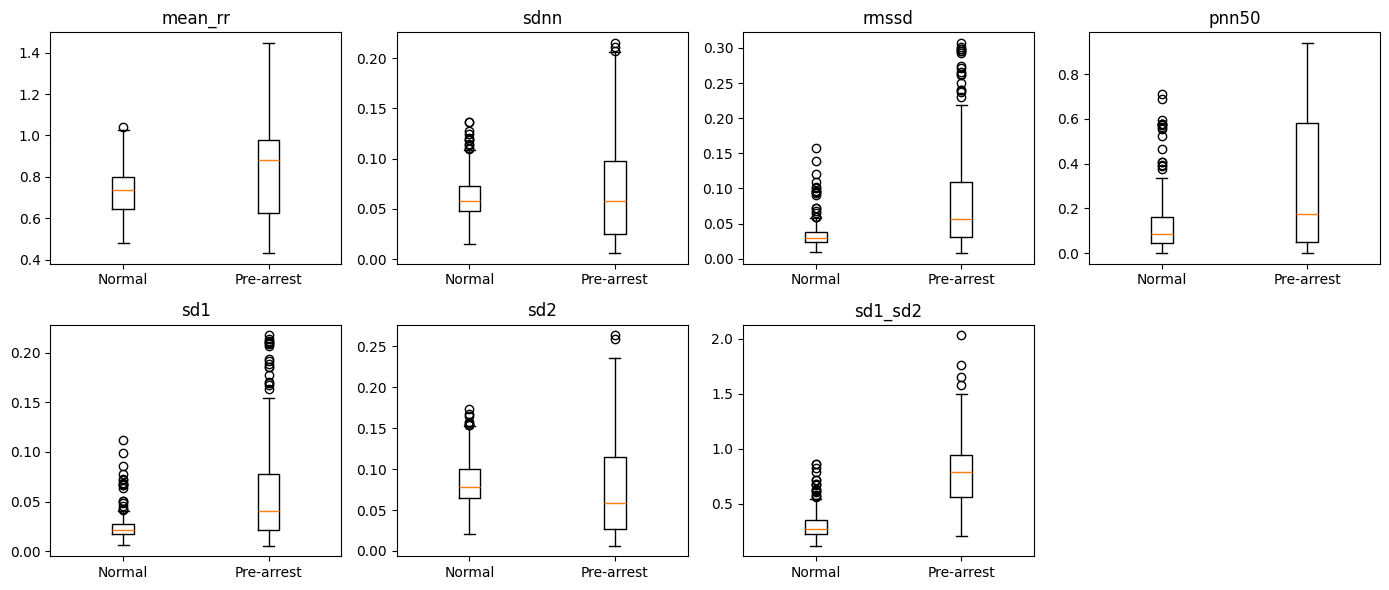

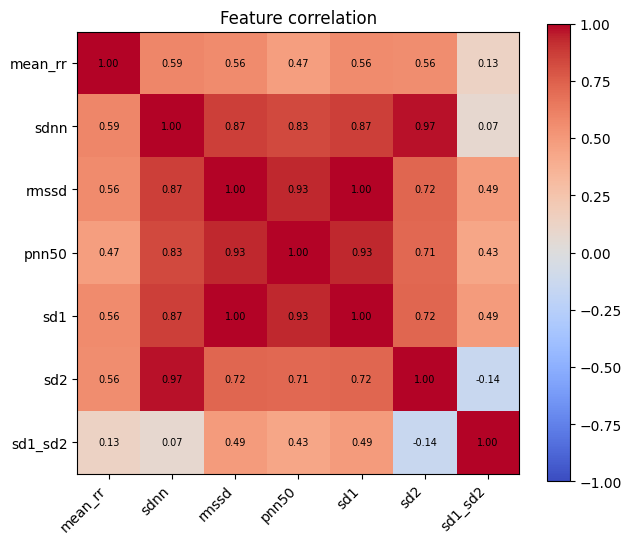

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for a, n in zip(ax.ravel(), NAMES):
    a.boxplot([df[df.y == 0][n], df[df.y == 1][n]]); a.set_xticks([1, 2]); a.set_xticklabels(CLS); a.set_title(n)
ax.ravel()[-1].axis("off"); save("03_feature_distributions")

c = df[NAMES].corr().values
plt.figure(figsize=(6.5, 5.5)); plt.imshow(c, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(7), NAMES, rotation=45, ha="right"); plt.yticks(range(7), NAMES)
for i in range(7):
    for j in range(7): plt.text(j, i, f"{c[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Feature correlation"); save("04_feature_correlation")


                      AUROC  AUPRC  threshold  accuracy  balanced_acc  precision  sensitivity  specificity     F1    MCC
Logistic Regression  0.929  0.939      0.433     0.867         0.868      0.897        0.843        0.893  0.869  0.735
SVM (RBF)            0.942  0.928      0.421     0.912         0.911      0.908        0.927        0.896  0.917  0.824
Random Forest        0.887  0.863      0.490     0.844         0.843      0.850        0.853        0.833  0.852  0.687
Extra Trees          0.905  0.884      0.487     0.861         0.861      0.875        0.860        0.863  0.867  0.722
Gradient Boosting    0.870  0.850      0.086     0.833         0.829      0.801        0.910        0.748  0.852  0.670

BEST MODEL: SVM (RBF) | threshold 0.421


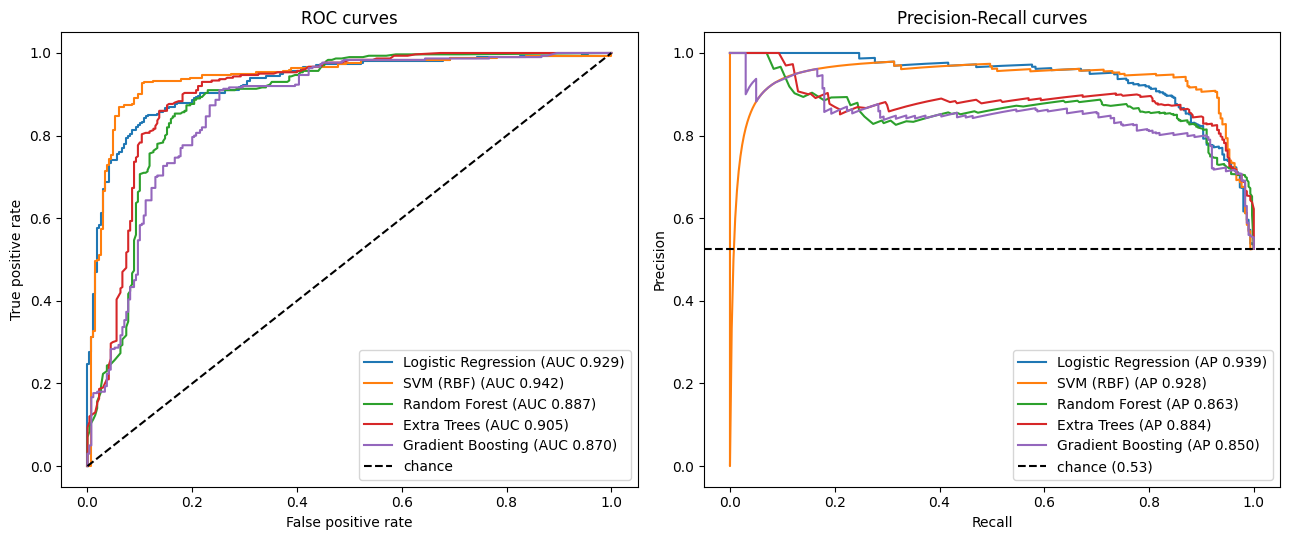

In [5]:
MODELS = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(probability=True, class_weight="balanced", random_state=0)),
    "Random Forest": RandomForestClassifier(300, class_weight="balanced", random_state=0),
    "Extra Trees": ExtraTreesClassifier(300, class_weight="balanced", random_state=0),
    "Gradient Boosting": GradientBoostingClassifier(random_state=0)}
cv = GroupKFold(5)
oof = {n: cross_val_predict(m, X, y, groups=g, cv=cv, method="predict_proba")[:, 1] for n, m in MODELS.items()}


def best_thr(y, p):                       # Youden's J
    fpr, tpr, thr = roc_curve(y, p); return float(thr[np.argmax(tpr - fpr)])


def metrics(y, p, thr):
    q = (p >= thr).astype(int)
    return {"AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p), "threshold": thr,
            "accuracy": accuracy_score(y, q), "balanced_acc": balanced_accuracy_score(y, q),
            "precision": precision_score(y, q), "sensitivity": recall_score(y, q),
            "specificity": recall_score(y, q, pos_label=0), "F1": f1_score(y, q), "MCC": matthews_corrcoef(y, q)}


table = pd.DataFrame({n: metrics(y, p, best_thr(y, p)) for n, p in oof.items()}).T.round(3)
table.to_csv(f"{REPORT}/model_comparison.csv"); print("\n", table.to_string())
best = table.AUROC.astype(float).idxmax(); pb = oof[best]; thr = float(table.loc[best, "threshold"])
print(f"\nBEST MODEL: {best} | threshold {thr:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for n, p in oof.items():
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y, p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f"{n} (AP {average_precision_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="chance"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves"); ax[0].legend()
ax[1].axhline(y.mean(), color="k", ls="--", label=f"chance ({y.mean():.2f})"); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves"); ax[1].legend()
save("05_roc_pr_all_models")

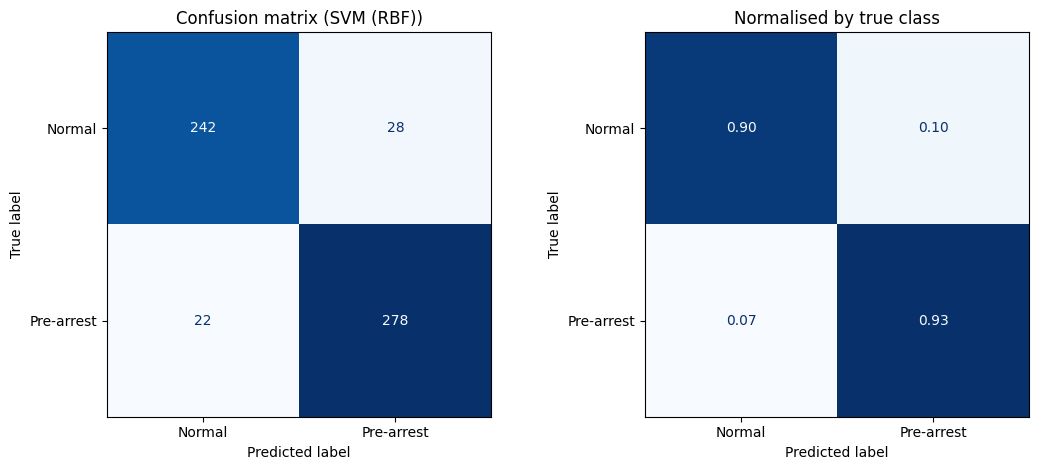

              precision    recall  f1-score   support

      Normal       0.92      0.90      0.91       270
  Pre-arrest       0.91      0.93      0.92       300

    accuracy                           0.91       570
   macro avg       0.91      0.91      0.91       570
weighted avg       0.91      0.91      0.91       570

AUROC 0.942 95% CI [0.885 0.981] | AUPRC 0.928 95% CI [0.838 0.987] (bootstrap over records)


In [6]:
pred = (pb >= thr).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLS, ax=ax[0], cmap="Blues", colorbar=False); ax[0].set_title(f"Confusion matrix ({best})")
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLS, normalize="true", ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f"); ax[1].set_title("Normalised by true class")
save("06_confusion_matrix")
print(classification_report(y, pred, target_names=CLS))

rng = np.random.default_rng(0); ids = np.unique(g); idx = {k: np.where(g == k)[0] for k in ids}; ba, bp = [], []
for _ in range(1000):                     # cluster bootstrap over records
    sm = np.concatenate([idx[k] for k in rng.choice(ids, len(ids))])
    if len(set(y[sm])) == 2: ba.append(roc_auc_score(y[sm], pb[sm])); bp.append(average_precision_score(y[sm], pb[sm]))
ci = lambda v: np.percentile(v, [2.5, 97.5]).round(3)
print(f"AUROC {roc_auc_score(y, pb):.3f} 95% CI {ci(ba)} | AUPRC {average_precision_score(y, pb):.3f} 95% CI {ci(bp)} (bootstrap over records)")

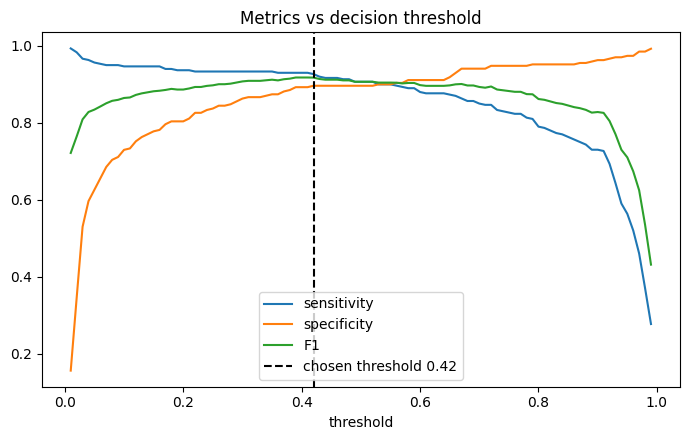

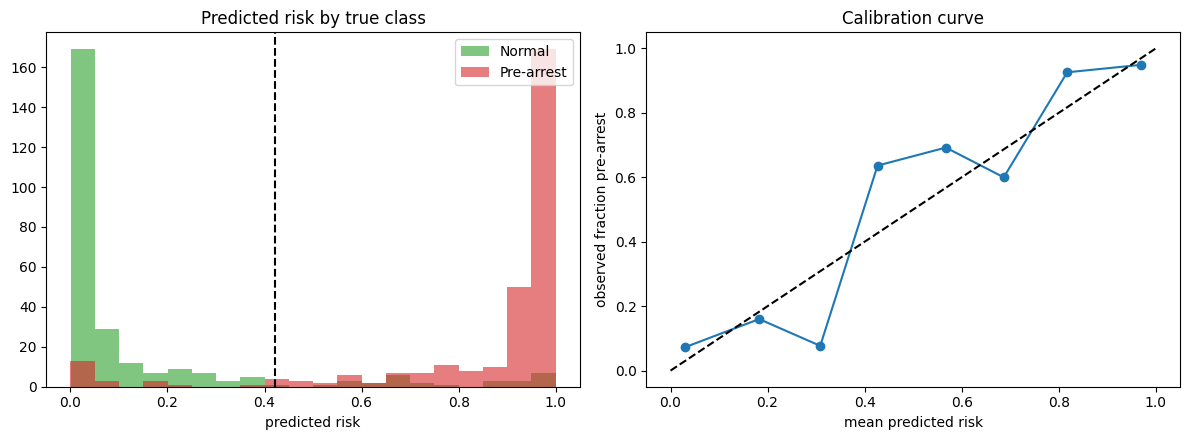

In [7]:
ts = np.linspace(0.01, 0.99, 99); q = [(pb >= t).astype(int) for t in ts]
plt.figure(figsize=(7, 4.5))
plt.plot(ts, [recall_score(y, z) for z in q], label="sensitivity"); plt.plot(ts, [recall_score(y, z, pos_label=0) for z in q], label="specificity")
plt.plot(ts, [f1_score(y, z) for z in q], label="F1"); plt.axvline(thr, color="k", ls="--", label=f"chosen threshold {thr:.2f}")
plt.xlabel("threshold"); plt.legend(); plt.title("Metrics vs decision threshold"); save("07_threshold_curves")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k in (0, 1): ax[0].hist(pb[y == k], bins=20, alpha=.6, color=COL[k], label=CLS[k])
ax[0].axvline(thr, color="k", ls="--"); ax[0].set(xlabel="predicted risk", title="Predicted risk by true class"); ax[0].legend()
pt, pp = calibration_curve(y, pb, n_bins=8); ax[1].plot(pp, pt, "o-"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set(xlabel="mean predicted risk", ylabel="observed fraction pre-arrest", title="Calibration curve")
save("08_risk_distribution_calibration")

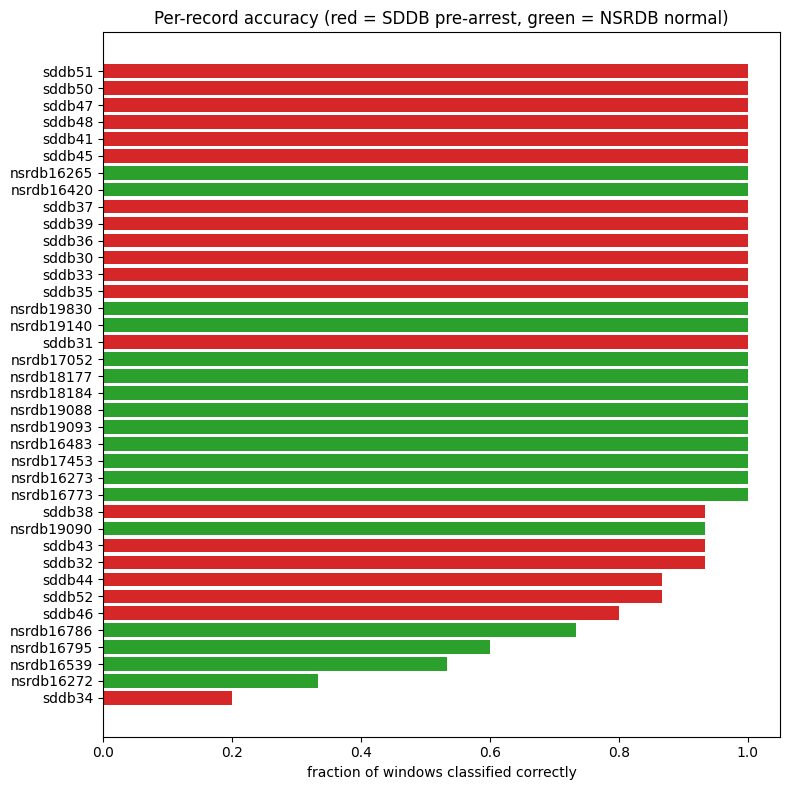

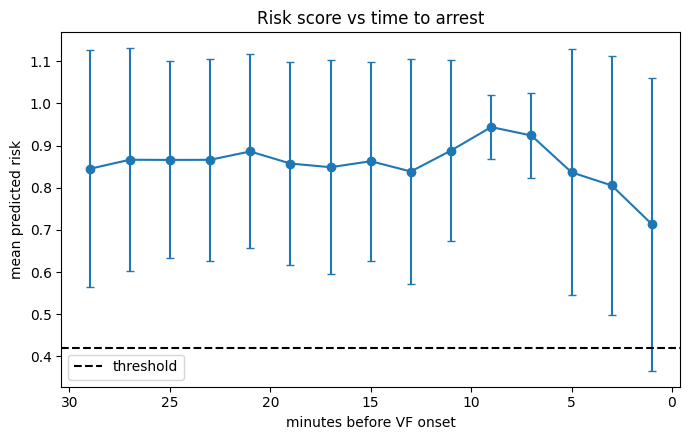

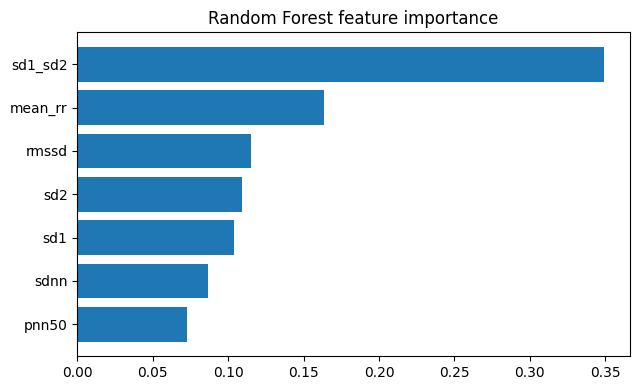

In [8]:
df["prob"], df["ok"] = pb, (pred == y).astype(int)
per = df.groupby("rec").agg(y=("y", "first"), acc=("ok", "mean")).sort_values("acc")
plt.figure(figsize=(8, 8)); plt.barh(per.index, per.acc, color=[COL[k] for k in per.y]); plt.xlabel("fraction of windows classified correctly")
plt.title("Per-record accuracy (red = SDDB pre-arrest, green = NSRDB normal)"); save("09_per_record_accuracy")

dp = df[df.y == 1].groupby("mins").prob.agg(["mean", "std"])
plt.figure(figsize=(7, 4.5)); plt.errorbar(dp.index, dp["mean"], yerr=dp["std"], fmt="o-", capsize=3); plt.axhline(thr, color="k", ls="--", label="threshold")
plt.gca().invert_xaxis(); plt.xlabel("minutes before VF onset"); plt.ylabel("mean predicted risk"); plt.legend(); plt.title("Risk score vs time to arrest")
save("10_risk_vs_time_to_arrest")

rf = RandomForestClassifier(300, class_weight="balanced", random_state=0).fit(X, y)
o = np.argsort(rf.feature_importances_)
plt.figure(figsize=(6.5, 4)); plt.barh(np.array(NAMES)[o], rf.feature_importances_[o]); plt.title("Random Forest feature importance"); save("11_feature_importance")

In [9]:
final = MODELS[best].fit(X, y)
joblib.dump({"model": final, "threshold": thr, "features": NAMES, "name": best}, f"{REPORT}/arrest_model.joblib")
shutil.make_archive("report", "zip", REPORT)
print("saved report.zip (all images, model_comparison.csv, features_dataset.csv, arrest_model.joblib)")
from google.colab import files
files.download("report.zip")

saved report.zip (all images, model_comparison.csv, features_dataset.csv, arrest_model.joblib)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>